# **Mapping Residential Development Trajectories as Indicators of Emerging and Future Business Markets**

Week 5

•	Cluster Analysis – K-Means Clustering Modeling

# **Loading Data**

In [3]:
import pandas as pd
import csv

# Loading the merged dataset with quoting configured to handle unclosed quotes
df_merged_final = pd.read_csv('bps_msa_units_value_merged_dataset.csv', quoting=csv.QUOTE_MINIMAL, on_bad_lines='skip')

# Displaying the head and info of the loaded DataFrame
print("Head of the loaded merged dataset:")
print(df_merged_final.head())
print("\nInfo of the loaded merged dataset:")
df_merged_final.info()

Head of the loaded merged dataset:
     CSA     CBSA                                               Name  year  \
0  101.0  10180.0  Abilene, TX                                   ...  2024   
1  101.0  10180.0  Abilene, TX                                   ...  2024   
2  101.0  10180.0  Abilene, TX                                   ...  2024   
3  101.0  10180.0  Abilene, TX                                   ...  2024   
4  101.0  10180.0  Abilene, TX                                   ...  2024   

   month        date residential_structure_type  units_count  value_usd State  \
0      1  2024-01-01                     1 Unit         28.0       7967    TX   
1      2  2024-02-01                     1 Unit         31.0       8617    TX   
2      3  2024-03-01                     1 Unit         18.0       5107    TX   
3      4  2024-04-01                     1 Unit         43.0      11923    TX   
4      5  2024-05-01                     1 Unit         33.0       9490    TX   

   units_

#**Data Preparation**

In [4]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Defining features for K-means clustering
features = [
    'units_count',
    'value_usd',
    'units_growth_1m',
    'units_growth_12m',
    'value_growth_1m',
    'value_growth_12m',
    'units_acceleration_1m',
    'value_acceleration_1m',
    'units_rolling_std_3m',
    'value_rolling_std_3m',
    'development_intensity'
]

# Creating a DataFrame with only the selected features
X = df_merged_final[features].copy()

# Replacing infinite values with NaN before imputation
X.replace([np.inf, -np.inf], np.nan, inplace=True)

# Handling missing values using median imputation
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Scaling the data using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Converting the scaled data back to a DataFrame for easier handling
df_scaled_features = pd.DataFrame(X_scaled, columns=features)

print("Shape of the prepared data for clustering:", df_scaled_features.shape)
print("\nHead of the scaled features DataFrame:")
print(df_scaled_features.head())
print("\nDescriptive statistics of the scaled features:")
print(df_scaled_features.describe())

Shape of the prepared data for clustering: (186404, 11)

Head of the scaled features DataFrame:
   units_count  value_usd  units_growth_1m  units_growth_12m  value_growth_1m  \
0    -0.095843  -0.068688        -0.065406         -0.073094        -0.053726   
1    -0.082251  -0.056435         0.005372         -0.073094        -0.022139   
2    -0.141150  -0.122600        -0.258149         -0.073094        -0.135664   
3    -0.027883   0.005885         0.646908         -0.073094         0.268812   
4    -0.073190  -0.039978        -0.164654         -0.073094        -0.088464   

   value_growth_12m  units_acceleration_1m  value_acceleration_1m  \
0         -0.036452               0.013247               0.009579   
1         -0.036452               0.013247               0.009579   
2         -0.036452              -0.163017              -0.069802   
3         -0.036452               0.678274               0.333199   
4         -0.036452              -0.557566              -0.259440   

  

#**Cluster Analysis**


Generating Elbow Plot for Year: 2020


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['units_growth_12m' 'value_growth_12m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


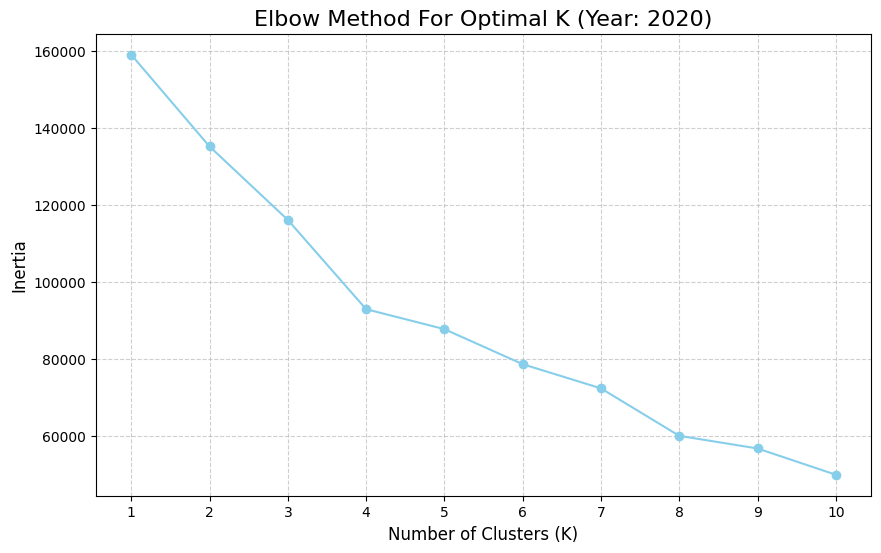


Generating Elbow Plot for Year: 2021


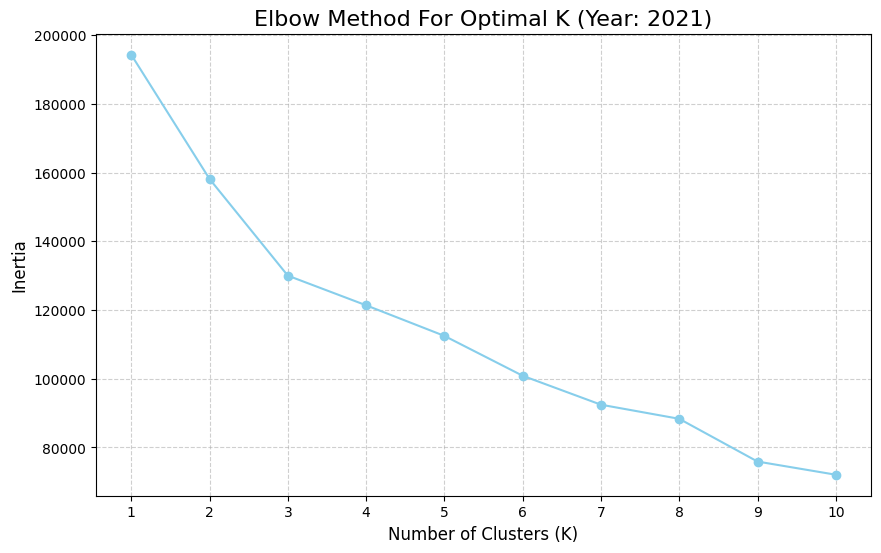


Generating Elbow Plot for Year: 2022


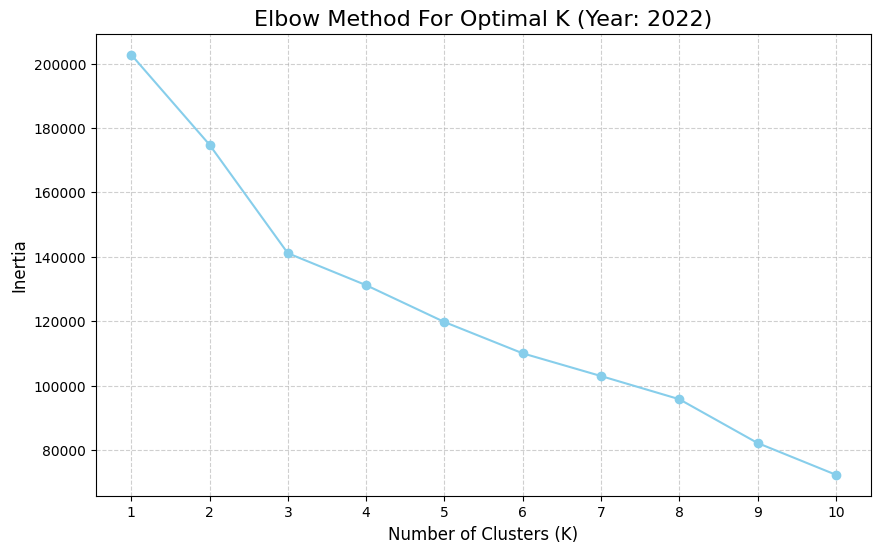


Generating Elbow Plot for Year: 2023


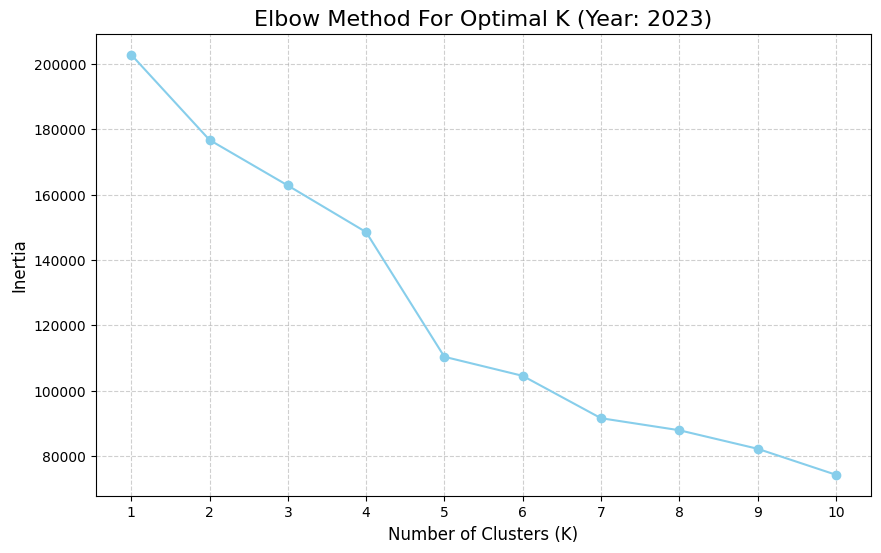


Generating Elbow Plot for Year: 2024


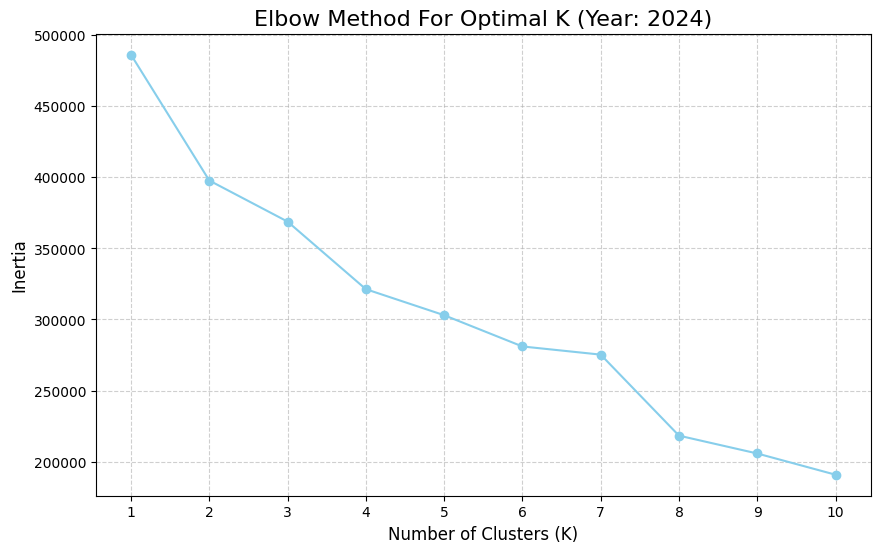


Generating Elbow Plot for Year: 2025


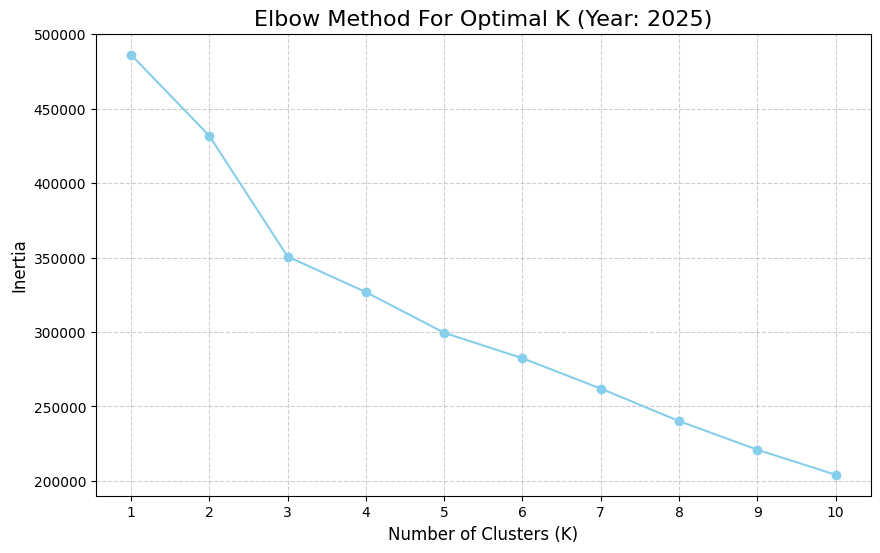


Generating Elbow Plot for Year: 2026


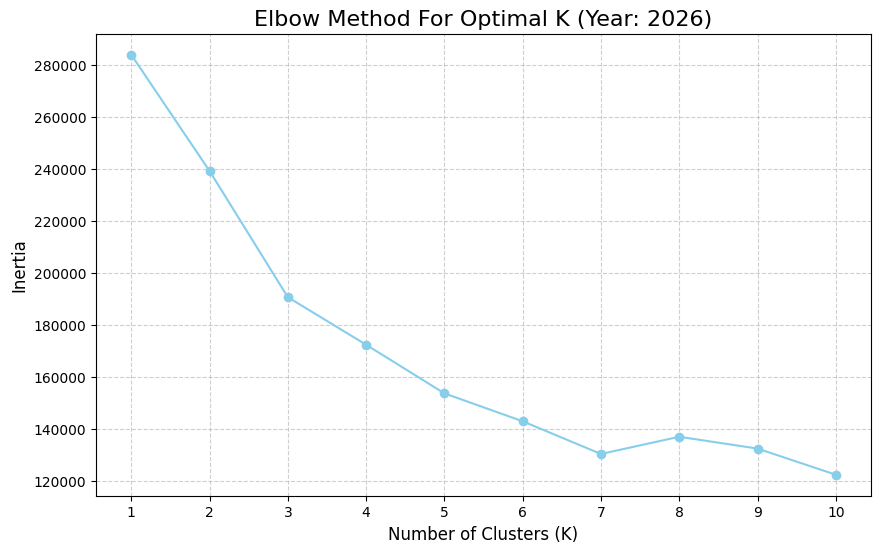

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

# Defining features for K-means clustering (re-using the 'features' list from earlier)
# Assuming 'features' is accessible from a previous cell.
features = [
    'units_count',
    'value_usd',
    'units_growth_1m',
    'units_growth_12m',
    'value_growth_1m',
    'value_growth_12m',
    'units_acceleration_1m',
    'value_acceleration_1m',
    'units_rolling_std_3m',
    'value_rolling_std_3m',
    'development_intensity'
]

# Determining a range of K values to test
k_range = range(1, 11)  # Test K from 1 to 10

# Getting all unique years in the merged DataFrame
years = sorted(df_merged_final['year'].unique())

for year in years:
    print(f"\nGenerating Elbow Plot for Year: {year}")

    # Filtering data for the current year
    df_year = df_merged_final[df_merged_final['year'] == year].copy()

    # Creating a DataFrame with only the selected features for the current year
    X_year = df_year[features].copy()

    # Replacing infinite values with NaN before imputation for the current year's data
    X_year.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Handling missing values using median imputation for the current year's data
    imputer = SimpleImputer(strategy='median')
    X_imputed_year = imputer.fit_transform(X_year)

    # Scaling the data using StandardScaler for the current year's data
    scaler = StandardScaler()
    df_scaled_features_year = scaler.fit_transform(X_imputed_year)

    # Calculating inertia for different K values for the current year
    inertia = []
    for k in k_range:
        # Initializing KMeans with the current k value
        kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
        # Fitting KMeans to the scaled data for the current year
        kmeans.fit(df_scaled_features_year)
        # Appending the inertia (sum of squared distances) to the list
        inertia.append(kmeans.inertia_)

    # Plotting the Elbow Method graph for the current year
    plt.figure(figsize=(10, 6))
    plt.plot(k_range, inertia, marker='o', linestyle='-', color='skyblue')
    plt.title(f'Elbow Method For Optimal K (Year: {year})', fontsize=16)
    plt.xlabel('Number of Clusters (K)', fontsize=12)
    plt.ylabel('Inertia', fontsize=12)
    plt.xticks(k_range)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()



In [6]:
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Defining k based on previous Elbow Method observation for the overall dataset
k = 4

# Defining features for K-means clustering (re-using the 'features' list from earlier)
# Assuming 'features' is accessible from a previous cell. If not, it needs to be redefined here:
features = [
    'units_count',
    'value_usd',
    'units_growth_1m',
    'units_growth_12m',
    'value_growth_1m',
    'value_growth_12m',
    'units_acceleration_1m',
    'value_acceleration_1m',
    'units_rolling_std_3m',
    'value_rolling_std_3m',
    'development_intensity'
]

# Getting all unique year-month combinations in the merged DataFrame
year_month_combinations = sorted(df_merged_final[['year', 'month']].drop_duplicates().values.tolist())

# Initializing an empty Series to store all cluster labels
all_clusters = pd.Series(index=df_merged_final.index, dtype=int)

print(f"Performing K-means clustering with k={k} for each month of each year separately...")

for year, month in year_month_combinations:
    print(f"\nProcessing year: {year}, month: {month}")

    # Filtering data for the current year and month
    df_month_year = df_merged_final[(df_merged_final['year'] == year) & (df_merged_final['month'] == month)].copy()

    # Creating a DataFrame with only the selected features for the current month's data
    X_month_year = df_month_year[features].copy()

    # Replacing infinite values with NaN before imputation for the current month's data
    X_month_year.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Handling missing values using median imputation for the current month's data
    imputer = SimpleImputer(strategy='median')
    X_imputed_month_year = imputer.fit_transform(X_month_year)

    # Scaling the data using StandardScaler for the current month's data
    scaler = StandardScaler()
    df_scaled_features_month_year = scaler.fit_transform(X_imputed_month_year)

    # Initializing and fit KMeans for the current month
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    clusters_month_year = kmeans.fit_predict(df_scaled_features_month_year)

    # Storing the cluster labels, mapping them back to the original DataFrame's index
    all_clusters.loc[df_month_year.index] = clusters_month_year

# Adding the month-specific cluster labels to the original merged DataFrame
df_merged_final['Cluster'] = all_clusters

print(f"\nK-means clustering completed for all month-year combinations with {k} clusters each.")
print("\nHead of the DataFrame with new 'Cluster' column (showing results for first few entries):")
print(df_merged_final[['Name', 'year', 'month', 'Cluster']].head())
print("\nNumber of observations per cluster (across all years combined):")
print(df_merged_final['Cluster'].value_counts().sort_index())

Performing K-means clustering with k=4 for each month of each year separately...

Processing year: 2020, month: 1

Processing year: 2020, month: 2

Processing year: 2020, month: 3

Processing year: 2020, month: 4

Processing year: 2020, month: 5

Processing year: 2020, month: 6

Processing year: 2020, month: 7

Processing year: 2020, month: 8

Processing year: 2020, month: 9

Processing year: 2020, month: 10

Processing year: 2020, month: 11

Processing year: 2020, month: 12

Processing year: 2021, month: 1

Processing year: 2021, month: 2

Processing year: 2021, month: 3

Processing year: 2021, month: 4

Processing year: 2021, month: 5


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['units_growth_1m' 'units_growth_12m' 'value_growth_1m' 'value_growth_12m'
 'units_acceleration_1m' 'value_acceleration_1m' 'units_rolling_std_3m'
 'value_rolling_std_3m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['units_growth_12m' 'value_growth_12m' 'units_acceleration_1m'
 'value_acceleration_1m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['units_growth_12m' 'value_growth_12m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/pyt


Processing year: 2021, month: 6

Processing year: 2021, month: 7

Processing year: 2021, month: 8

Processing year: 2021, month: 9

Processing year: 2021, month: 10

Processing year: 2021, month: 11

Processing year: 2021, month: 12

Processing year: 2022, month: 1

Processing year: 2022, month: 2

Processing year: 2022, month: 3

Processing year: 2022, month: 4

Processing year: 2022, month: 5

Processing year: 2022, month: 6

Processing year: 2022, month: 7

Processing year: 2022, month: 8

Processing year: 2022, month: 9

Processing year: 2022, month: 10

Processing year: 2022, month: 11

Processing year: 2022, month: 12

Processing year: 2023, month: 1

Processing year: 2023, month: 2

Processing year: 2023, month: 3

Processing year: 2023, month: 4

Processing year: 2023, month: 5

Processing year: 2023, month: 6

Processing year: 2023, month: 7

Processing year: 2023, month: 8

Processing year: 2023, month: 9

Processing year: 2023, month: 10

Processing year: 2023, month: 11

P

In [7]:
import numpy as np

# Replacing infinite values with NaN in the original df_merged_final for the relevant features
for col in features:
    if col in df_merged_final.columns:
        df_merged_final[col].replace([np.inf, -np.inf], np.nan, inplace=True)


/tmp/ipykernel_2084/2550050812.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_merged_final[col].replace([np.inf, -np.inf], np.nan, inplace=True)


In [8]:
# Defining the original features for clarity within this cell
original_features = features

# Recalculating cluster centers with the cleaned df_merged_final
# Grouping the df_merged_final by 'Cluster' and calculating the mean for the original features
cluster_centers_original_scale_cleaned = df_merged_final.groupby('Cluster')[original_features].mean()

print("Mean values of features per cluster (original scale) after NaN replacement:")
print(cluster_centers_original_scale_cleaned)

# Median (for robustness against outliers)
print("\nMedian values of features per cluster (original scale) after NaN replacement:")
print(df_merged_final.groupby('Cluster')[original_features].median())


Mean values of features per cluster (original scale) after NaN replacement:
         units_count     value_usd  units_growth_1m  units_growth_12m  \
Cluster                                                                 
0.0        25.002332   6063.328542         0.079486          0.177470   
1.0       141.524857  32409.272243         0.759970          0.747485   
2.0       332.311747  78579.446348         1.085621          1.829938   
3.0       175.483136  40093.753228         1.256864          1.564163   

         value_growth_1m  value_growth_12m  units_acceleration_1m  \
Cluster                                                             
0.0             0.165142          0.374187              -0.263346   
1.0             1.397882          1.426297               0.300087   
2.0             1.980079          3.775460               0.156490   
3.0             1.859183          2.593916               0.612917   

         value_acceleration_1m  units_rolling_std_3m  value_rolling_st

In [9]:
# Saving Data with CLusters
df_merged_final.to_csv("clustered_df_merged_final.csv", index = False)

#**Visualizing Clusters**

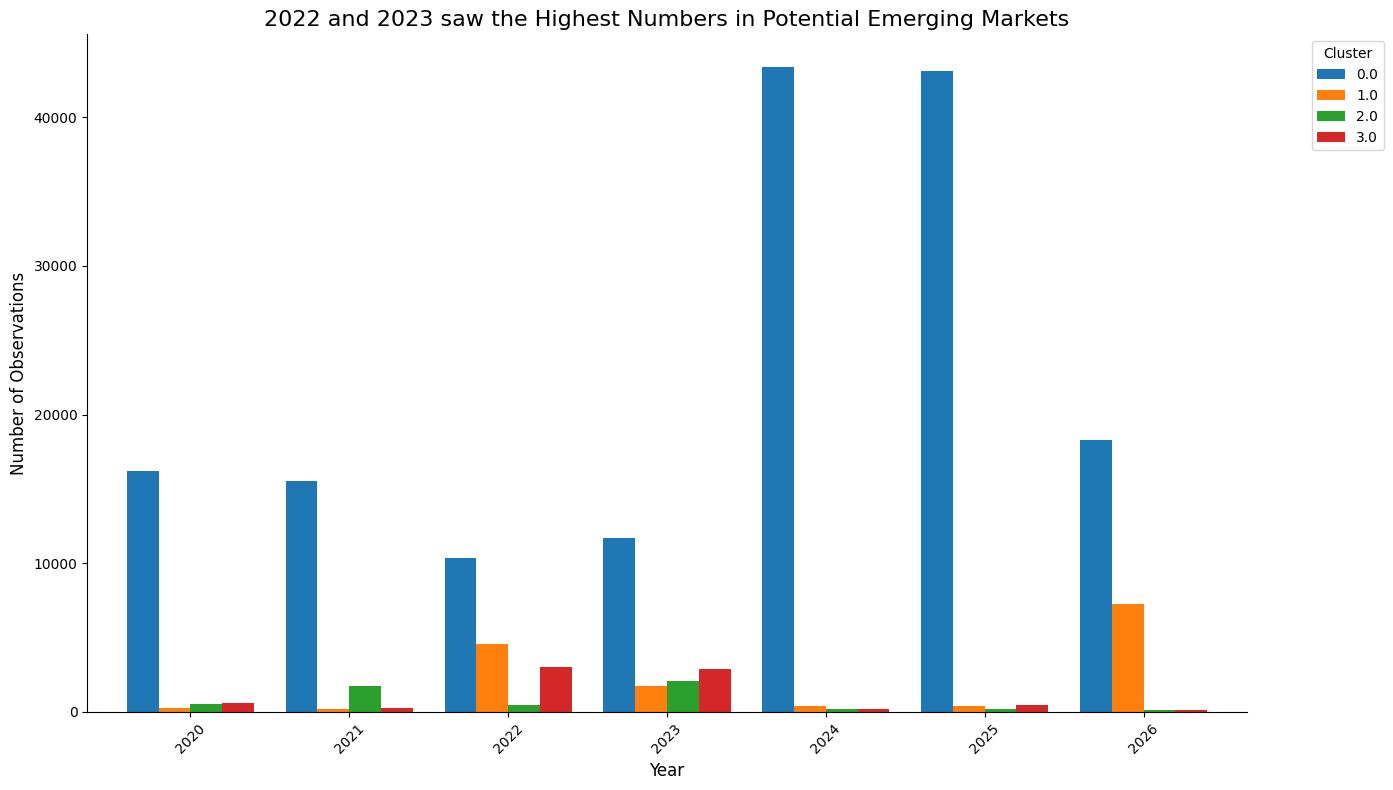

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Step 1: Counting individual clusters by year ---
# Group by 'year' and 'Cluster', then count the occurrences of each cluster.
cluster_counts_by_year = df_merged_final.groupby(['year', 'Cluster']).size().unstack(fill_value=0)

# --- Step 2: Creating the grouped column chart ---
fig, ax = plt.subplots(figsize=(14, 8))
cluster_counts_by_year.plot(kind='bar', ax=ax, width=0.8)

# Customizing the plot for professionalism
ax.set_title('2022 and 2023 saw the Highest Numbers in Potential Emerging Markets', fontsize=16)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of Observations', fontsize=12)
ax.tick_params(axis='x', rotation=45) # Rotate x-axis labels if they overlap
ax.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

In [11]:
# Saving Cluster Counts Data Data
cluster_counts_by_year.to_csv("cluster_counts_by_year.csv", index = False)

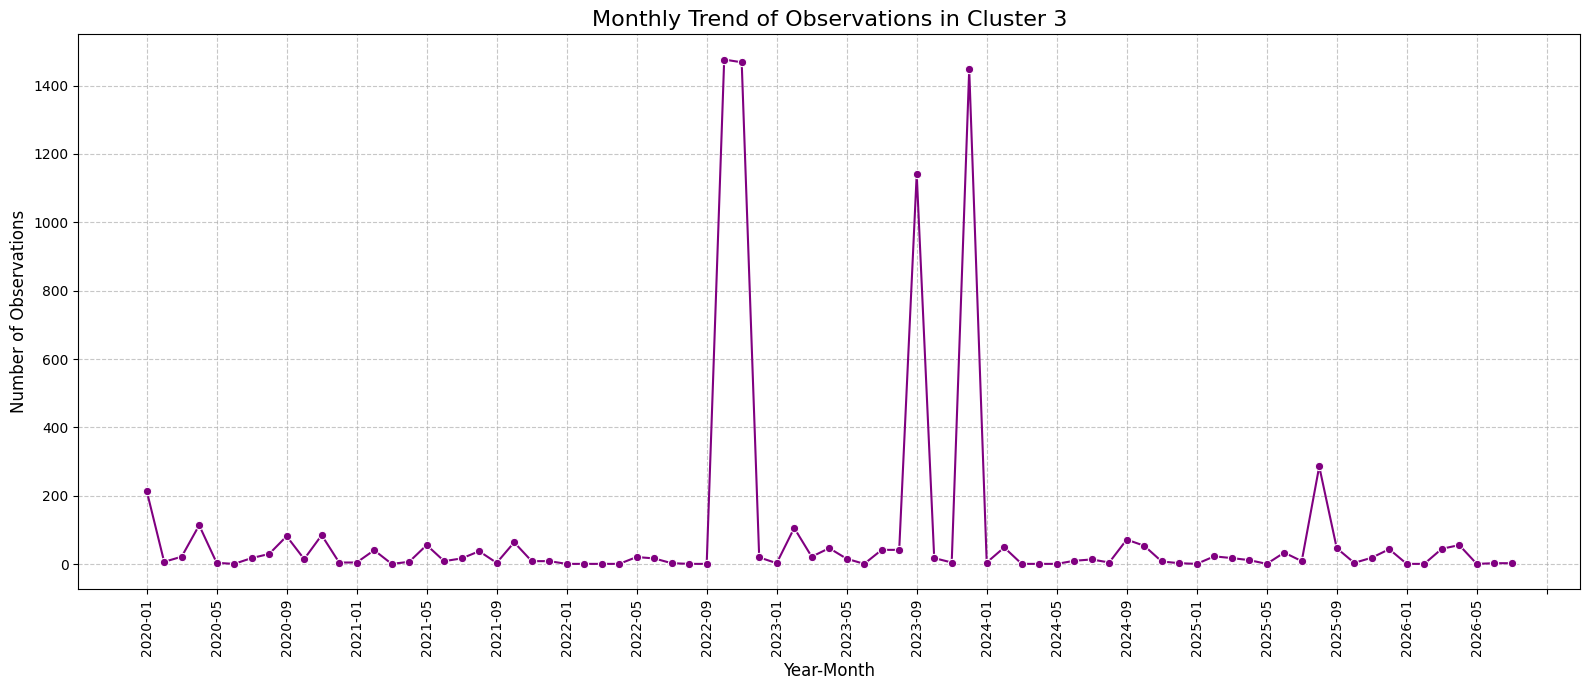

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filtering for Cluster 3
df_cluster_3 = df_merged_final[df_merged_final['Cluster'] == 3.0].copy()

# Grouping by year and month, then count the occurrences
df_cluster_3['year'] = df_cluster_3['year'].astype(int)
df_cluster_3['month'] = df_cluster_3['month'].astype(int)

cluster_3_counts_monthly = df_cluster_3.groupby(['year', 'month']).size().reset_index(name='Count')

# Creating a combined 'YearMonth' column for the x-axis, formatted as 'YYYY-MM'
cluster_3_counts_monthly['YearMonth'] = cluster_3_counts_monthly.apply(lambda row: f"{row['year']}-{row['month']:02d}", axis=1)

# Sorting by YearMonth to ensure correct chronological order on the plot
cluster_3_counts_monthly = cluster_3_counts_monthly.sort_values(by='YearMonth')

# Creating the line plot
plt.figure(figsize=(16, 7))
sns.lineplot(data=cluster_3_counts_monthly, x='YearMonth', y='Count', marker='o', color='purple')

# Customizing the plot for professionalism
plt.title('Monthly Trend of Observations in Cluster 3', fontsize=16)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Number of Observations', fontsize=12)
plt.xticks(rotation=90) # Rotate x-axis labels for better readability

n_ticks = len(cluster_3_counts_monthly['YearMonth'])
if n_ticks > 30:
    plt.gca().xaxis.set_major_locator(plt.MaxNLocator(nbins=n_ticks // 3))

plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [13]:
import geopandas
import requests
import os
from io import BytesIO
import zipfile

# URL of the shapefile provided by the user
shapefile_url = 'https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_us_cbsa_500k.zip'

# Downloading the shapefile zip file
response = requests.get(shapefile_url)
response.raise_for_status() # Raise an exception for HTTP errors

# Creating a BytesIO object from the downloaded content
zip_file = zipfile.ZipFile(BytesIO(response.content))

# Extracting all files to a temporary directory
import tempfile
with tempfile.TemporaryDirectory() as tmpdir:
    zip_file.extractall(tmpdir)

    # Finding the .shp file within the extracted directory
    shp_file_path = None
    for root, dirs, files in os.walk(tmpdir):
        for file in files:
            if file.endswith('.shp'):
                shp_file_path = os.path.join(root, file)
                break
        if shp_file_path:
            break

    if shp_file_path:
        # Loading the shapefile into a GeoDataFrame
        gdf_cbsa = geopandas.read_file(shp_file_path)
        print("GeoDataFrame loaded successfully.")
        print(gdf_cbsa.head())
        print("\nInfo of GeoDataFrame:")
        gdf_cbsa.info()
    else:
        raise FileNotFoundError("Shapefile (.shp) not found in the downloaded zip archive.")

GeoDataFrame loaded successfully.
  CSAFP CBSAFP        AFFGEOID  GEOID                  NAME  \
0  None  43620  310M600US43620  43620       Sioux Falls, SD   
1   357  12660  310M600US12660  12660           Baraboo, WI   
2   184  17460  310M600US17460  17460  Cleveland-Elyria, OH   
3   174  16860  310M600US16860  16860    Chattanooga, TN-GA   
4   324  29340  310M600US29340  29340      Lake Charles, LA   

                          NAMELSAD LSAD       ALAND      AWATER  \
0       Sioux Falls, SD Metro Area   M1  6670256887    27900457   
1           Baraboo, WI Micro Area   M2  2153686013    45692969   
2  Cleveland-Elyria, OH Metro Area   M1  5176805788  5128428315   
3    Chattanooga, TN-GA Metro Area   M1  5409949983   126699774   
4      Lake Charles, LA Metro Area   M1  6083163521  1766798991   

                                            geometry  
0  POLYGON ((-97.60873 43.81839, -97.60858 43.840...  
1  POLYGON ((-90.3124 43.64099, -90.3023 43.64116...  
2  POLYGON ((-82.34

In [14]:
# Saving Geo Data
gdf_cbsa.to_csv("gdf_cbsa.csv", index = False)

In [15]:
import geopandas

# Cleaning the 'Name' column in df_merged_final and gdf_cbsa data
df_merged_final['Name_cleaned'] = df_merged_final['Name'].str.replace('...', '', regex=False).str.strip()
gdf_cbsa['NAME_cleaned'] = gdf_cbsa['NAME'].str.strip()

# Merging df_merged_final with gdf_cbsa
clustered_gdf = df_merged_final.merge(gdf_cbsa[['NAME_cleaned', 'geometry']],
                                     left_on='Name_cleaned',
                                     right_on='NAME_cleaned',
                                     how='left')

# Converting the merged DataFrame to a GeoDataFrame
clustered_gdf = geopandas.GeoDataFrame(clustered_gdf, geometry='geometry')

# Droping the cleaned name columns used for merging if no longer needed
clustered_gdf = clustered_gdf.drop(columns=['Name_cleaned', 'NAME_cleaned'])

print("Head of the clustered GeoDataFrame:")
print(clustered_gdf.head())
print("\nInfo of the clustered GeoDataFrame:")
clustered_gdf.info()
clustered_gdf.to_csv("clustered_gdf.csv", index = False)

Head of the clustered GeoDataFrame:
     CSA     CBSA                                               Name  year  \
0  101.0  10180.0  Abilene, TX                                   ...  2024   
1  101.0  10180.0  Abilene, TX                                   ...  2024   
2  101.0  10180.0  Abilene, TX                                   ...  2024   
3  101.0  10180.0  Abilene, TX                                   ...  2024   
4  101.0  10180.0  Abilene, TX                                   ...  2024   

   month        date residential_structure_type  units_count  value_usd State  \
0      1  2024-01-01                     1 Unit         28.0       7967    TX   
1      2  2024-02-01                     1 Unit         31.0       8617    TX   
2      3  2024-03-01                     1 Unit         18.0       5107    TX   
3      4  2024-04-01                     1 Unit         43.0      11923    TX   
4      5  2024-05-01                     1 Unit         33.0       9490    TX   

   ...  